# Mobilidade urbana e mercado imobiliário no Rio de Janeiro
Este notebook registra as verificações e os testes realizados.
Objetivo desta etapa: preparar as bases de Metrô, BRT, VLT e BRS para o cruzamento futuro com os dados do ITBI.

Caminho seguido: inspeção das bases → revisão das datas/geometrias → padronização e recortes → mapas → teste de distância com OpenStreetMap.


## 1. Bases e exploração inicial
Fontes: Metrô, BRT, VLT e BRS, no Data.Rio. Arquivos originais em data/raw

In [1]:
from pathlib import Path
import math
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import networkx as nx
import osmnx as ox


from pathlib import Path

RAIZ = Path.cwd().resolve()

if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent

RAW = RAIZ / "data" / "raw"
MOBILIDADE = RAIZ / "data" / "processed" / "mobilidade"
CACHE_OSMNX = RAIZ / "cache" / "osmnx"

# Compatibilidade com as variáveis antigas
pasta = RAW
pasta_processados = MOBILIDADE
pasta_dados = MOBILIDADE
pasta_cache = CACHE_OSMNX

MOBILIDADE.mkdir(parents=True, exist_ok=True)
CACHE_OSMNX.mkdir(parents=True, exist_ok=True)


### 1.1 Metrô

In [2]:
arquivo_metro = pasta / "Esta%C3%A7%C3%B5es_Metr%C3%B4.geojson"
metro = gpd.read_file(arquivo_metro)
print("Registros:", len(metro), "| CRS:", metro.crs)
display(metro[["nome", "flg_ativa", "data_inauguracao", "geometry"]].head())


Registros: 41 | CRS: EPSG:4326


,nome,flg_ativa,data_inauguracao,geometry
0,Pavuna,1,1998,POINT (-43.36489 -22.80663)
1,Engenheiro Rubens Paiva,1,1998,POINT (-43.35849 -22.81628)
2,Acari / Fazenda Botafogo,1,1998,POINT (-43.34968 -22.82453)
3,Coelho Neto,1,1998,POINT (-43.3433 -22.83149)
4,Colégio,1,1998,POINT (-43.3339 -22.8427)


In [3]:
print(metro[["status", "data_inc"]].isna().sum())

print("Estações por situação:")
print(metro["flg_ativa"].value_counts(dropna=False))

print("\nTipos de geometria:")
print(metro.geometry.geom_type.value_counts())

print("\nEstações sem geometria:")
print(metro.geometry.isna().sum())

print("Anos de inauguração registrados:")
print(metro["data_inauguracao"].value_counts(dropna=False).sort_index())

print("\nInaugurações a partir de 2011:")
display(metro.loc[metro["data_inauguracao"] >= 2011,
    ["nome", "data_inauguracao"]].sort_values("data_inauguracao"))


status      41
data_inc    41
dtype: int64
Estações por situação:
flg_ativa
1    41
Name: count, dtype: int64

Tipos de geometria:
Point    41
Name: count, dtype: int64

Estações sem geometria:
0
Anos de inauguração registrados:
data_inauguracao
1979    5
1980    2
1981    7
1982    3
1983    3
1988    1
1991    1
1996    2
1998    7
2003    1
2007    1
2009    2
2014    1
2016    5
Name: count, dtype: int64

Inaugurações a partir de 2011:


,nome,data_inauguracao
35,Uruguai,2014
36,Nossa Senhora da Paz,2016
37,Jardim de Alah,2016
38,Antero de Quental,2016
39,São Conrado,2016
40,Jardim Oceânico,2016


### 1.2 BRT

In [4]:
arquivo_brt = pasta / "Esta%C3%A7%C3%B5es_BRT (1).geojson"

brt = gpd.read_file(arquivo_brt)

print("Registros:", len(brt))
print("Sistema de coordenadas:", brt.crs)

print("\nColunas:")
print(brt.columns.tolist())

print("\nTipos de geometria:")
print(brt.geometry.geom_type.value_counts())

display(brt.head())


Registros: 156
Sistema de coordenadas: EPSG:4326

Colunas:
['fid', 'tipo', 'ano', 'lote_oper', 'corredor', 'nome', 'populacao', 'geometry']

Tipos de geometria:
MultiPoint    156
Name: count, dtype: int64


,fid,tipo,ano,lote_oper,corredor,nome,populacao,geometry
0,1,Terminal,2023,2,Transbrasil,Terminal Deodoro,None,MULTIPOINT ((-43.38428 -22.85369))
1,2,Estação,2024,2,Transbrasil,Guadalupe,None,MULTIPOINT ((-43.37717 -22.84505))
2,3,Estação,2024,2,Transbrasil,Jardim Guadalupe,None,MULTIPOINT ((-43.36868 -22.83978))
3,4,Estação,2024,2,Transbrasil,Fazenda Botafogo,None,MULTIPOINT ((-43.35085 -22.83104))
4,5,Estação,2024,2,Transbrasil,Ceasa-Irajá,None,MULTIPOINT ((-43.33262 -22.82436))


In [5]:
print("Tipos de parada:")
print(brt["tipo"].value_counts(dropna=False))

print("\nCorredores:")
print(brt["corredor"].value_counts(dropna=False))

print("\nAnos cadastrados:")
print(brt["ano"].value_counts(dropna=False).sort_index())

print("\nRegistros sem geometria:")
print(brt.geometry.isna().sum())

import pandas as pd

# Converter os anos para números
brt["ano_num"] = pd.to_numeric(brt["ano"], errors="coerce")

# Selecionar registros com ano ausente, inválido ou após 2024
problemas = brt[
    brt["ano_num"].isna() | (brt["ano_num"] > 2024)
]

display(problemas[["nome", "tipo", "corredor", "ano"]])

print("Quantidade de pontos por geometria:")

print(
    brt.geometry.apply(lambda g: len(g.geoms)).value_counts()
)


Tipos de parada:
tipo
Estação     138
Terminal     18
Name: count, dtype: int64

Corredores:
corredor
Transoeste       66
Transcarioca     49
Transbrasil      22
Transolimpica    19
Name: count, dtype: int64

Anos cadastrados:
ano
2012    65
2014    49
2016    19
2023     1
2024    18
2026     1
x        1
NaN      2
Name: count, dtype: int64

Registros sem geometria:
0
Quantidade de pontos por geometria:
geometry
1    156
Name: count, dtype: int64


,nome,tipo,corredor,ano
152,Terminal Margaridas,Terminal,Transbrasil,NaN
153,Terminal Missões,Terminal,Transbrasil,NaN
154,FUTURO Terminal Santa Cruz,Terminal,Transoeste,x
155,Caju,Estação,Transbrasil,2026


### 1.3 VLT e BRS

In [6]:

# Encontrar os arquivos
arquivo_vlt = next(pasta.glob("*VLT*"))
arquivo_brs = next(pasta.glob("BRS*"))

# Carregar as bases
vlt = gpd.read_file(arquivo_vlt)
brs = gpd.read_file(arquivo_brs)

print("VLT:", len(vlt), "registros")
print("BRS:", len(brs), "registros")

print("\nGeometrias do VLT:")
print(vlt.geometry.geom_type.value_counts())

print("\nGeometrias do BRS:")
print(brs.geometry.geom_type.value_counts())

print("\nSistemas de coordenadas:")
print("VLT:", vlt.crs)
print("BRS:", brs.crs)


VLT: 31 registros
BRS: 25 registros

Geometrias do VLT:
Point    31
Name: count, dtype: int64

Geometrias do BRS:
LineString         24
MultiLineString     1
Name: count, dtype: int64

Sistemas de coordenadas:
VLT: EPSG:4326
BRS: EPSG:4326


In [7]:
print("COLUNAS DO VLT:")
print(vlt.columns.tolist())

display(vlt.head())

print("\nCOLUNAS DO BRS:")
print(brs.columns.tolist())

display(brs.head())

print("Situação operacional do VLT:")
print(vlt["em_operação"].value_counts(dropna=False))

print("\nNomes das paradas:")
print(vlt["nome"].tolist())

print("\nValores nas colunas de linha:")
for coluna in ["linha_1", "linha_2", "linha_3", "linha_4"]:
    print(coluna)
    print(vlt[coluna].value_counts(dropna=False))


COLUNAS DO VLT:
['objectid', 'nome', 'integra_metro', 'integra_barcas', 'integra_onibus', 'integra_trem', 'integra_teleferico', 'integra_aeroporto', 'linha_1', 'linha_2', 'linha_3', 'linha_4', 'em_operação', 'geometry']

COLUNAS DO BRS:
['fid', 'ext__km_', 'data_de_pu', 'data_da_po', 'nº_faixas', 'corredor', 'início', 'fim', 'ap', 'fid_', 'vias', 'name', 'portaria_s', 'id', 'SHAPE__Length', 'início_op', 'geometry']
Situação operacional do VLT:
em_operação
1    31
Name: count, dtype: int64

Nomes das paradas:
['Gamboa', 'Rodoviária', 'Cordeiro da Graça', 'Santo Cristo', 'Pereira Reis', 'Vila Olímpica', 'Praia Formosa', 'Equador', 'Cidade do Samba', 'Utopia AquaRio', 'Providência', 'Harmonia', 'Parada dos Navios', 'Parada dos Museus', 'Candelária', 'Sete de Setembro', 'Cinelândia', 'Carioca', 'Central', 'Saara', 'Tiradentes', 'Colombo', 'Praça XV', 'Itamaraty', 'Camerino', 'Santa Rita', 'Santos Dumont', 'Antônio Carlos', 'São Bento', 'Terminal Gentileza', 'Cristiano Ottoni Pequena África

,objectid,nome,integra_metro,integra_barcas,integra_onibus,integra_trem,integra_teleferico,integra_aeroporto,linha_1,linha_2,linha_3,linha_4,em_operação,geometry
0,1,Gamboa,0,0,0,0,0,0,1,1,2,Sim,1,POINT (-43.19938 -22.89797)
1,2,Rodoviária,0,0,1,0,0,0,1,1,2,Sim,1,POINT (-43.20738 -22.89882)
2,3,Cordeiro da Graça,0,0,0,0,0,0,1,1,2,Sim,1,POINT (-43.20422 -22.89712)
3,4,Santo Cristo,0,0,0,0,0,0,1,1,2,Sim,1,POINT (-43.2003 -22.89534)
4,5,Pereira Reis,0,0,0,0,0,0,1,1,2,Sim,1,POINT (-43.20182 -22.89666)


,fid,ext__km_,data_de_pu,data_da_po,nº_faixas,corredor,início,fim,ap,fid_,vias,name,portaria_s,id,SHAPE__Length,início_op,geometry
0,1,3.372853,2011-03-14 00:00:00+00:00,2011-03-11 00:00:00+00:00,2,Copacabana I,Rua Francisco Otaviano,Av. Princesa Isabel,2.1,0,Av. Nossa Senhora de Copacabana,Nossa Senhora de Copacabana,6.713,1,3372.852756,01/03/2011,"LINESTRING (-43.18985 -22.98665, -43.19009 -22.98587, -43.19015 -22.98568, -43.19015 -22.98567, -43.19023 -22.98542, -43.19027 -22.98527, -43.1903 -22.98516, -43.19041 -22.9848, -43.19066 -22.98396, -43.19067 -22.98395, -43.19074 -22.98371, -43.19082 -22.98344, -43.19095 -22.98298, -43.19096 -22.98296, -43.19103 -22.98272, -43.19109 -22.9824, -43.19111 -22.98227, -43.19115 -22.98203, -43.19117 -22.9818, -43.19117 -22.98179, -43.19118 -22.98147, -43.19118 -22.98125, -43.19118 -22.98124, -43.19117 -22.98079, -43.19117 -22.98076, -43.19116 -22.98057, -43.19115 -22.98019, -43.19113 -22.97992, -43.19112 -22.97971, -43.19108 -22.97952, -43.19092 -22.97896, -43.19088 -22.97884, -43.19081 -22.9785, -43.19073 -22.97818, -43.19067 -22.97794, -43.1904 -22.97692, -43.19017 -22.976, -43.19011 -22.97588, -43.19004 -22.97577, -43.18957 -22.97496, -43.18954 -22.9749, -43.18922 -22.97439, -43.18899 -22.974, -43.18825 -22.97287, -43.18797 -22.97246, -43.18781 -22.97222, -43.18762 -22.97194, -43.18746 -22.9717, -43.18728 -22.97147, -43.18711 -22.97129, -43.18641 -22.97062, -43.18637 -22.97058, -43.18604 -22.97026, -43.18573 -22.96999, -43.18467 -22.96911, -43.18382 -22.96857, -43.18351 -22.96837, -43.18298 -22.96803, -43.18253 -22.96775, -43.18226 -22.96757, -43.18202 -22.96741, -43.1819 -22.96733, -43.1817 -22.96722, -43.18159 -22.96719, -43.18058 -22.96715, -43.18052 -22.96713, -43.17955 -22.96662, -43.17908 -22.96637, -43.17888 -22.96627, -43.17886 -22.96626, -43.17831 -22.96595, -43.17787 -22.9657, -43.17707 -22.96524, -43.17689 -22.96515, -43.17654 -22.96499, -43.17585 -22.96468, -43.17484 -22.96424, -43.17482 -22.96423, -43.1744 -22.96404)"
1,2,3.969309,NaT,NaT,1/2,Copacabana II,Av. Princesa Isabel,Rua Teresa Aragão,2.1,0,"Praça Demétrio Ribeiro, Barata Ribeiro, Tn. Sá Freire Alvim, Raul Pompéia, Av. Rainha Elizabeth",Barata Ribeiro,,2,3969.308903,9/4/2011,"LINESTRING (-43.17561 -22.9614, -43.17563 -22.9616, -43.1757 -22.96181, -43.17581 -22.96216, -43.17589 -22.96222, -43.17674 -22.96277, -43.17726 -22.96313, -43.17768 -22.96341, -43.178 -22.96361, -43.17871 -22.96406, -43.17879 -22.96411, -43.17896 -22.96423, -43.17973 -22.96473, -43.18014 -22.96499, -43.1803 -22.96509, -43.1808 -22.96541, -43.18112 -22.96562, -43.18126 -22.96571, -43.18163 -22.96594, -43.1817 -22.96599, -43.18261 -22.96659, -43.18307 -22.96691, -43.18309 -22.96692, -43.18355 -22.96721, -43.18435 -22.96774, -43.18483 -22.96805, -43.18521 -22.96829, -43.18585 -22.9687, -43.18675 -22.96929, -43.18705 -22.96948, -43.18748 -22.96976, -43.18788 -22.97002, -43.18812 -22.97017, -43.18826 -22.97026, -43.18858 -22.9706, -43.18924 -22.97129, -43.18999 -22.97206, -43.19078 -22.97289, -43.19097 -22.97325, -43.19135 -22.97394, -43.19153 -22.97428, -43.19196 -22.97508, -43.19211 -22.97535, -43.1923 -22.9757, -43.19248 -22.9764, -43.19264 -22.97699, -43.19265 -22.97704, -43.19274 -22.9774, -43.19274 -22.97744, -43.19283 -22.97778, -43.19285 -22.97783, -43.19287 -22.9779, -43.1929 -22.97807, -43.19278 -22.9791, -43.19277 -22.97924, -43.19268 -22.98003, -43.19262 -22.98065, -43.19259 -22.98093, -43.19249 -22.98119, -43.19249 -22.98119, -43.1924 -22.98151, -43.19224 -22.98207, -43.19203 -22.98277, -43.19198 -22.98296, -43.1919 -22.98322, -43.1919 -22.98322, -43.1916 -22.9842, -43.1916 -22.9842, -43.19148 -22.9846, -43.19146 -22.98468, -43.19136 -22.98499, -43.19136 -22.98503, -43.19136 -22.98506, -43.19138 -22.98508, -43.1914 -22.98509, -43.19623 -22.98641)"
2,3,1.564689,2011-08-18 00:00:00+00:00,2011-08-17 00:00:00+00:00,1,Leblon,Av. Visconde de Albuquerque,Av. Borges de Medeiros,2.1,0,Ataulfo de Paiva,Ataulfo de Paiva,8.646,3,1564.689490,20/

## 2. Tratamentos e pendências
Recorte imobiliário: 2011–2024. Guardamos as bases originais; anos faltantes, inválidos ou posteriores a 2024 são excluídos somente das análises temporais.


### 2.1. BRT — ano e geometria
Quatro registros precisam de revisão (dois sem ano, um com x e Caju/2026). Os 156 MultiPoint têm um ponto cada; para as análises datadas até 2024, selecionamos 152 registros.

In [8]:
# Selecionar registros com anos entre 2011 e 2024
brt_historico = brt[
    brt["ano_num"].between(2011, 2024)
].copy()

# Converter MultiPoint para Point
brt_historico["geometry"] = brt_historico.geometry.apply(
    lambda geom: geom.geoms[0] if geom.geom_type == "MultiPoint" else geom
)

print("Registros originais:", len(brt))
print("Registros selecionados:", len(brt_historico))

print("\nTipos de geometria:")
print(brt_historico.geometry.geom_type.value_counts())

print("\nSistema de coordenadas:")
print(brt_historico.crs)


Registros originais: 156
Registros selecionados: 152

Tipos de geometria:
Point    152
Name: count, dtype: int64

Sistema de coordenadas:
EPSG:4326


### 2.2. VLT — complementação de anos
A fonte geográfica não informa inauguração. Os anos foram levantados em fontes históricas; Itamaraty permanece sem data. A atribuição individual das datas deve ser validada antes de conclusões históricas.

In [9]:
# Anos de inauguração verificados em fontes históricas
anos_vlt = {
    "Santos Dumont": 2016,
    "Parada dos Museus": 2016,
    "Praça XV": 2017,
    "Saara": 2017,
    "Tiradentes": 2017,
    "Colombo": 2017,
    "Central": 2017,
    "Cristiano Ottoni Pequena África": 2019,
    "Camerino": 2019,
    "Santa Rita": 2019,
    "Terminal Gentileza": 2024
}

vlt["ano_inicio"] = vlt["nome"].map(anos_vlt)


# Complementar os anos com fontes históricas

novos_anos_vlt = {
    # Paradas em operação em 2016
    "Rodoviária": 2016,
    "Santo Cristo": 2016,
    "Pereira Reis": 2016,
    "Equador": 2016,
    "Cidade do Samba": 2016,
    "Utopia AquaRio": 2016,
    "Parada dos Navios": 2016,
    "Candelária": 2016,
    "Sete de Setembro": 2016,
    "Cinelândia": 2016,
    "Carioca": 2016,
    "Antônio Carlos": 2016,
    "São Bento": 2016,

    # Paradas em operação em 2017
    "Providência": 2017,
    "Harmonia": 2017,
    "Vila Olímpica": 2017,
    "Praia Formosa": 2017,
    "Gamboa": 2016,
    "Cordeiro da Graça": 2017
}

# Preencher apenas os anos que estavam ausentes
vlt["ano_inicio"] = vlt["ano_inicio"].fillna(
    vlt["nome"].map(novos_anos_vlt)
)

print("Paradas com ano identificado:",
      vlt["ano_inicio"].notna().sum())

print("\nParadas ainda sem ano:")
display(vlt.loc[vlt["ano_inicio"].isna(), ["nome"]])


Paradas com ano identificado: 30

Paradas ainda sem ano:


,nome
23,Itamaraty



Fontes consultadas:

- Prefeitura do Rio (2016): operação da Linha 1 e
  expansão até a Rodoviária.
  https://www.rio.rj.gov.br/web/guest/exibeconteudo?id=6268057

- Prefeitura do Rio (2016): operação da parada Gamboa.
  https://www.rio.rj.gov.br/web/guest/exibeconteudo?id=6548374

- Prefeitura do Rio (2017): início da operação das
  paradas Providência e Harmonia.
  https://www.rio.rj.gov.br/web/guest/exibeconteudo?id=7056533

- Prefeitura do Rio (2019): inauguração da Linha 3.
  https://en.prefeitura.rio/transportes/prefeitura-inicia-operacao-da-linha-3-do-vlt-que-liga-a-central-do-brasil-ao-aeroporto-santos-dumont/

- Prefeitura do Rio (2024): inauguração do
  Terminal Intermodal Gentileza.
  https://prefeitura.rio/cidade/prefeitura-inaugura-o-terminal-intermodal-gentileza/

Os anos indicam o início de operação.

### 2.3. BRS — datas inconsistentes
Centro-Tijuca informa duas datas; Passos contém 10/06/0200. Não atribuímos um ano presumido a esses registros. BRS é representado por linhas, não por pontos de estação.

In [10]:
# Transformar datas de texto em datas reconhecidas pelo Python
brs["inicio_operacao_dt"] = pd.to_datetime(
    brs["início_op"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

print("Registros sem data válida:")
print(brs["inicio_operacao_dt"].isna().sum())

print("\nCorredores por ano de início:")
print(
    brs["inicio_operacao_dt"]
    .dt.year
    .value_counts(dropna=False)
    .sort_index()
)

print("\nCorredores com datas ausentes:")
display(
    brs.loc[
        brs["inicio_operacao_dt"].isna(),
        ["name", "início_op"]
    ]
)

# BRS: datas suspeitas ou não reconhecidas
display(
    brs.loc[
        (brs["inicio_operacao_dt"].dt.year < 2010) |
        brs["inicio_operacao_dt"].isna(),
        ["name", "início_op", "inicio_operacao_dt"]
    ]
)

# VLT: valores diferentes de Sim e Não
display(
    vlt.loc[
        ~vlt["linha_4"].isin(["Sim", "Não"]),
        ["nome", "linha_4"]
    ]
)


Registros sem data válida:
1

Corredores por ano de início:
inicio_operacao_dt
200.0     1
2011.0    7
2012.0    4
2013.0    3
2014.0    2
2015.0    2
2016.0    1
2019.0    1
2022.0    3
NaN       1
Name: count, dtype: int64

Corredores com datas ausentes:


,name,início_op
11,Centro-Tijuca,26/8/2013 e 24/9/2013


,name,início_op,inicio_operacao_dt
11,Centro-Tijuca,26/8/2013 e 24/9/2013,NaT
20,Passos,10/06/0200,200-06-10


,nome,linha_4
30,Cristiano Ottoni Pequena África,1


In [11]:
display(
    brs.loc[
        brs["name"].isin(["Passos", "Centro-Tijuca"]),
        ["name", "corredor", "início_op", "data_de_pu", "data_da_po"]
    ]
)

# Criar uma coluna com o ano identificado
brs["ano_inicio_utilizavel"] = (
    brs["inicio_operacao_dt"].dt.year.astype("Int64")
)

# Manter apenas os anos dentro do período analisado
brs.loc[
    ~brs["ano_inicio_utilizavel"]
    .between(2011, 2024)
    .fillna(False),
    "ano_inicio_utilizavel"
] = pd.NA

print("Anos utilizáveis:")
print(brs["ano_inicio_utilizavel"].value_counts().sort_index())

print("\nRegistros que precisam de revisão:")
display(
    brs.loc[
        brs["ano_inicio_utilizavel"].isna(),
        ["name", "início_op"]
    ]
)


Anos utilizáveis:
ano_inicio_utilizavel
2011    7
2012    4
2013    3
2014    2
2015    2
2016    1
2019    1
2022    3
Name: count, dtype: Int64

Registros que precisam de revisão:


,name,corredor,início_op,data_de_pu,data_da_po
11,Centro-Tijuca,Centro / Tijuca,26/8/2013 e 24/9/2013,2013-08-21 00:00:00+00:00,2013-08-20 00:00:00+00:00
20,Passos,Passos,10/06/0200,2022-06-13 00:00:00+00:00,2022-06-09 00:00:00+00:00


,name,início_op
11,Centro-Tijuca,26/8/2013 e 24/9/2013
20,Passos,10/06/0200


## 3. Padronização e exportação
As geometrias são projetadas para EPSG:31983 (metros). Mantemos BRS separado; Metrô, BRT e VLT são reunidos em uma base de pontos.

In [12]:
# Selecionar as informações necessárias do metrô
metro_preparado = metro[
    ["nome", "data_inauguracao", "geometry"]
].copy()

# Selecionar as informações necessárias do BRT
brt_preparado = brt_historico[
    ["nome", "tipo", "corredor", "ano_num", "geometry"]
].copy()

# Converter as coordenadas para um sistema em metros
metro_metros = metro_preparado.to_crs(epsg=31983)
brt_metros = brt_preparado.to_crs(epsg=31983)

print("Metrô:", metro_metros.crs)
print("BRT:", brt_metros.crs)

display(metro_metros.head())
pasta_dados = RAIZ / "data" / "processed" / "mobilidade"

# Salvar versões tratadas de Metrô e BRT
metro_metros.to_file(pasta_processados / "metro_preparado.gpkg", driver="GPKG")
brt_metros.to_file(pasta_processados / "brt_preparado.gpkg", driver="GPKG")
print("Metrô e BRT salvos em", pasta_processados.resolve())


Metrô: EPSG:31983
BRT: EPSG:31983
Metrô e BRT salvos em C:\Users\angel\OneDrive\Documentos\ChatGPT\AEDV\verificacao_reproducao\data\processed\mobilidade


,nome,data_inauguracao,geometry
0,Pavuna,1998,POINT (667822.317 7476957.304)
1,Engenheiro Rubens Paiva,1998,POINT (668467.04 7475881.901)
2,Acari / Fazenda Botafogo,1998,POINT (669361.144 7474958.053)
3,Coelho Neto,1998,POINT (670007.976 7474180.389)
4,Colégio,1998,POINT (670958.307 7472928.257)


In [13]:
vlt_preparado = vlt[["nome", "em_operação", "ano_inicio", "geometry"]].to_crs(epsg=31983)
brs_preparado = brs[["name", "corredor", "início_op",
                     "ano_inicio_utilizavel", "geometry"]].to_crs(epsg=31983)

vlt_preparado.to_file(pasta_processados / "vlt_preparado.gpkg", driver="GPKG")
brs_preparado.to_file(pasta_processados / "brs_preparado.gpkg", driver="GPKG")
print("VLT e BRS salvos com sucesso")


VLT e BRS salvos com sucesso


### 3.1. Base integrada de estações e paradas

In [14]:
# Metrô
metro_pontos = metro[
    ["nome", "data_inauguracao", "geometry"]
].copy()

metro_pontos["modal"] = "Metrô"
metro_pontos = metro_pontos.rename(
    columns={"data_inauguracao": "ano_inicio"}
)

# BRT
brt_pontos = brt[
    ["nome", "ano_num", "geometry"]
].copy()

brt_pontos["modal"] = "BRT"
brt_pontos = brt_pontos.rename(
    columns={"ano_num": "ano_inicio"}
)

# Converter MultiPoint para Point
brt_pontos["geometry"] = brt_pontos.geometry.apply(
    lambda g: g.geoms[0] if g.geom_type == "MultiPoint" else g
)

# VLT
vlt_pontos = vlt[
    ["nome", "ano_inicio", "geometry"]
].copy()

vlt_pontos["modal"] = "VLT"


# Juntar as bases
pontos_transporte = gpd.GeoDataFrame(
    pd.concat([
        metro_pontos,
        brt_pontos,
        vlt_pontos
    ], ignore_index=True),
    geometry="geometry",
    crs="EPSG:4326"
)

# Converter coordenadas para metros
pontos_transporte = pontos_transporte.to_crs(
    epsg=31983
)

print("Total de registros:", len(pontos_transporte))

print("\nRegistros por transporte:")
print(pontos_transporte["modal"].value_counts())

display(pontos_transporte.head())


Total de registros: 228

Registros por transporte:
modal
BRT      156
Metrô     41
VLT       31
Name: count, dtype: int64


,nome,ano_inicio,geometry,modal
0,Pavuna,1998.0,POINT (667822.317 7476957.304),Metrô
1,Engenheiro Rubens Paiva,1998.0,POINT (668467.04 7475881.901),Metrô
2,Acari / Fazenda Botafogo,1998.0,POINT (669361.144 7474958.053),Metrô
3,Coelho Neto,1998.0,POINT (670007.976 7474180.389),Metrô
4,Colégio,1998.0,POINT (670958.307 7472928.257),Metrô


In [15]:
pontos_transporte.to_file(
    pasta_processados / "pontos_transporte.gpkg",
    driver="GPKG"
)

print("Base integrada salva com sucesso!")

# Resumo da base integrada
resumo = pontos_transporte.groupby("modal").agg(
    registros=("nome", "size"),
    sem_ano=(
        "ano_inicio",
        lambda col: pd.to_numeric(
            col, errors="coerce"
        ).isna().sum()
    )
)

display(resumo)

print("Geometrias ausentes:",
      pontos_transporte.geometry.isna().sum())

print("Sistema de coordenadas:",
      pontos_transporte.crs)


Base integrada salva com sucesso!
Geometrias ausentes: 0
Sistema de coordenadas: EPSG:31983


,registros,sem_ano
modal,,
BRT,156,3
Metrô,41,0
VLT,31,1


### 3.2. Recorte temporal

A base de pontos reúne Metrô, BRT e VLT; BRS permanece separado por representar linhas. As contagens são calculadas nas células seguintes. Somente registros com ano de operação conhecido são considerados disponíveis em cada ano.

In [16]:
def transporte_ate_ano(ano):
    # Transformar a coluna de ano em número
    anos_inicio = pd.to_numeric(
        pontos_transporte["ano_inicio"],
        errors="coerce"
    )

    # Selecionar os pontos que já existiam até aquele ano
    filtro = (
        anos_inicio.notna() &
        (anos_inicio <= ano)
    )

    return pontos_transporte.loc[filtro].copy()


# Testar diferentes anos
for ano in [2011, 2014, 2016, 2024]:
    pontos = transporte_ate_ano(ano)

    print(f"\nAno: {ano}")
    print(pontos["modal"].value_counts())



Ano: 2011
modal
Metrô    35
Name: count, dtype: int64

Ano: 2014
modal
BRT      114
Metrô     36
Name: count, dtype: int64

Ano: 2016
modal
BRT      133
Metrô     41
VLT       16
Name: count, dtype: int64

Ano: 2024
modal
BRT      152
Metrô     41
VLT       30
Name: count, dtype: int64


In [17]:
# Converter a coluna de ano para números
anos_inicio = pd.to_numeric(
    pontos_transporte["ano_inicio"],
    errors="coerce"
)

# Selecionar estações inauguradas até 2024
pontos_ate_2024 = pontos_transporte[
    anos_inicio.between(1900, 2024)
].copy()

print("Base original:", len(pontos_transporte))
print("Base até 2024:", len(pontos_ate_2024))

print("\nRegistros por modal:")
print(pontos_ate_2024["modal"].value_counts())

print("\nRegistros que ficaram fora:")
display(
    pontos_transporte.loc[
        ~anos_inicio.between(1900, 2024),
        ["nome", "modal", "ano_inicio"]
    ]
)

pontos_ate_2024.to_file(
    pasta_processados / "pontos_transporte_ate_2024.gpkg",
    driver="GPKG"
)

print("Base histórica preparada e salva!")


Base original: 228
Base até 2024: 223

Registros por modal:
modal
BRT      152
Metrô     41
VLT       30
Name: count, dtype: int64

Registros que ficaram fora:
Base histórica preparada e salva!


,nome,modal,ano_inicio
193,Terminal Margaridas,BRT,NaN
194,Terminal Missões,BRT,NaN
195,FUTURO Terminal Santa Cruz,BRT,NaN
196,Caju,BRT,2026.0
220,Itamaraty,VLT,NaN


## 4. Visualizações preliminares
Mapas exploratórios da infraestrutura registrada nas bases atuais, não reconstruções exatas da rede de cada ano

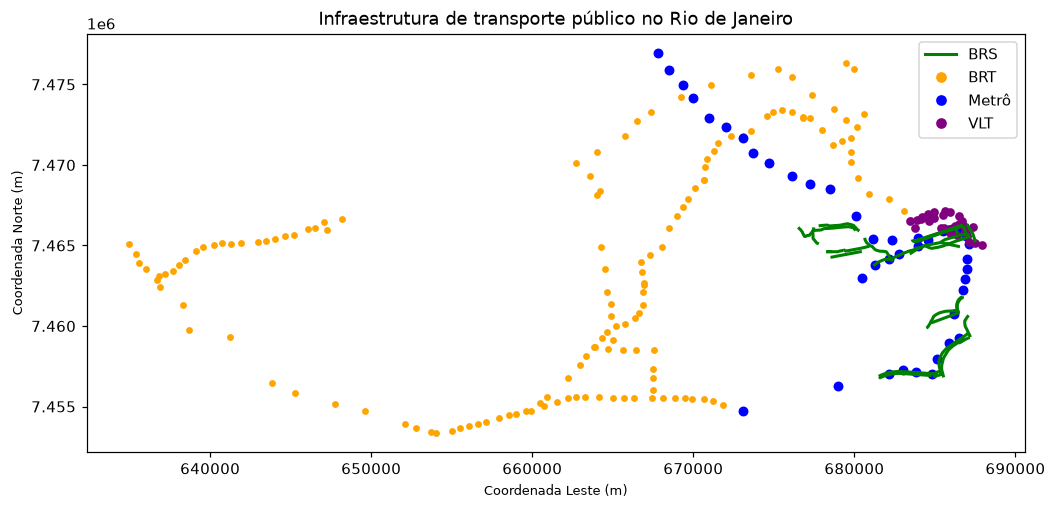

In [18]:
from matplotlib.lines import Line2D

# Converter VLT e BRS para coordenadas em metros
vlt_metros = vlt.to_crs(epsg=31983)
brs_metros = brs.to_crs(epsg=31983)

fig, ax = plt.subplots(figsize=(11, 9))

# Corredores BRS
brs_metros.plot(ax=ax, color="green", linewidth=2)

# Estações BRT
brt_metros.plot(ax=ax, color="orange", markersize=12)

# Estações Metrô
metro_metros.plot(ax=ax, color="blue", markersize=30)

# Paradas VLT
vlt_metros.plot(ax=ax, color="purple", markersize=22)

legenda = [
    Line2D([0], [0], color="green", lw=2, label="BRS"),
    Line2D([0], [0], marker="o", color="orange",
           linestyle="", label="BRT"),
    Line2D([0], [0], marker="o", color="blue",
           linestyle="", label="Metrô"),
    Line2D([0], [0], marker="o", color="purple",
           linestyle="", label="VLT")
]

ax.legend(handles=legenda)

ax.set_title("Infraestrutura de transporte público no Rio de Janeiro")
ax.set_xlabel("Coordenada Leste (m)")
ax.set_ylabel("Coordenada Norte (m)")

plt.show()


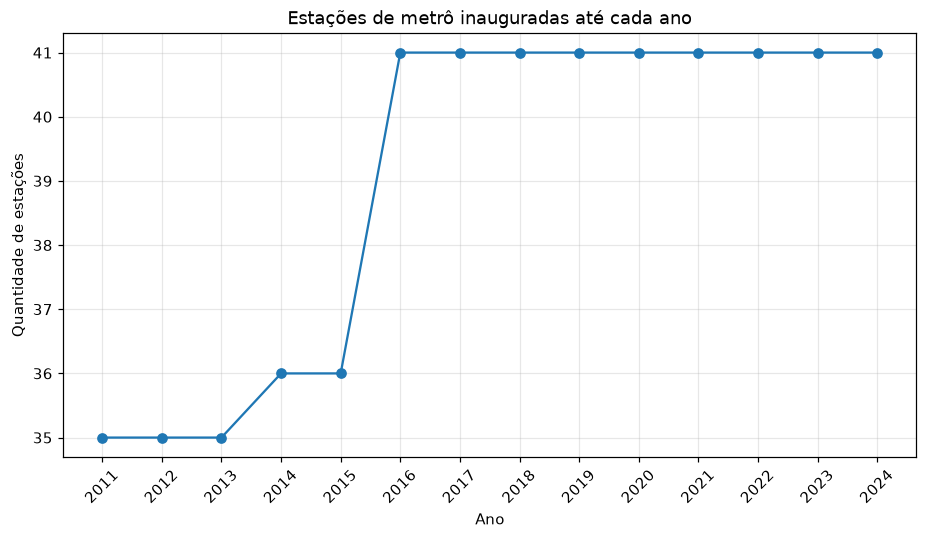

In [19]:
# Anos da análise imobiliária
anos = list(range(2011, 2025))

# Converter datas de inauguração em números
metro["ano_inauguracao"] = pd.to_numeric(
    metro["data_inauguracao"],
    errors="coerce"
)

# Contar estações inauguradas até cada ano
quantidades = []

for ano in anos:
    quantidade = (
        metro["ano_inauguracao"] <= ano
    ).sum()

    quantidades.append(quantidade)

# Visualização
plt.figure(figsize=(10, 5))

plt.plot(anos, quantidades, marker="o")

plt.title("Estações de metrô inauguradas até cada ano")
plt.xlabel("Ano")
plt.ylabel("Quantidade de estações")
plt.xticks(anos, rotation=45)
plt.grid(alpha=0.3)

plt.show()


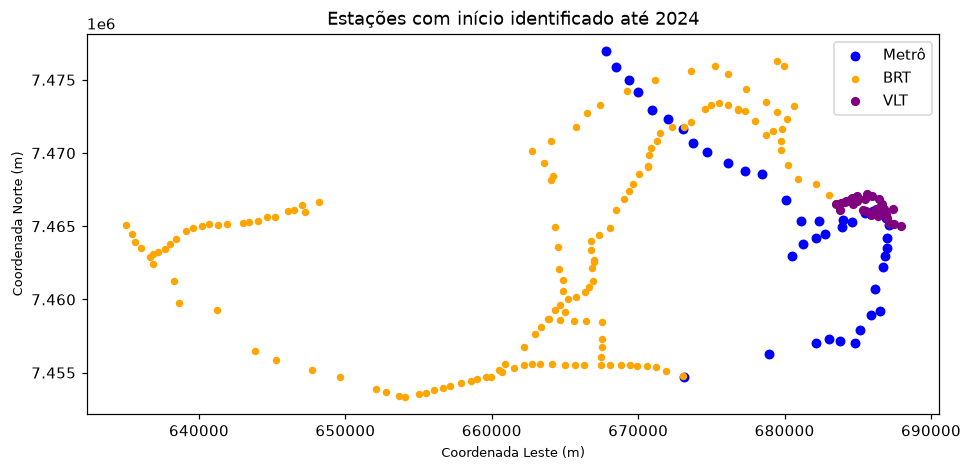

In [20]:
fig, ax = plt.subplots(figsize=(10, 8))

# Metrô
pontos_ate_2024[
    pontos_ate_2024["modal"] == "Metrô"
].plot(
    ax=ax,
    color="blue",
    markersize=30,
    label="Metrô"
)

# BRT
pontos_ate_2024[
    pontos_ate_2024["modal"] == "BRT"
].plot(
    ax=ax,
    color="orange",
    markersize=15,
    label="BRT"
)

# VLT
pontos_ate_2024[
    pontos_ate_2024["modal"] == "VLT"
].plot(
    ax=ax,
    color="purple",
    markersize=25,
    label="VLT"
)

ax.set_title(
    "Estações com início identificado até 2024"
)

ax.set_xlabel("Coordenada Leste (m)")
ax.set_ylabel("Coordenada Norte (m)")

ax.legend()
plt.show()


## 5. Teste com OpenStreetMap (OSMnx)
Teste ilustrativo, sem imóveis do ITBI: comparar linha reta × menor caminho pela rede de pedestres perto da estação Nossa Senhora da Paz. O ponto de origem foi escolhido artificialmente.

In [21]:
# Estação de referência (coordenadas geográficas)
estacao = metro.loc[metro["nome"] == "Nossa Senhora da Paz", "geometry"].iloc[0]
ponto = (estacao.y, estacao.x)
print("Estação:", ponto)

# Aproveitar o arquivo já salvo para evitar baixar a rede novamente
ox.settings.use_cache = True
arquivo_rede = pasta_cache / "rede_caminhada_ipanema.graphml"
if arquivo_rede.exists():
    G = ox.io.load_graphml(filepath=str(arquivo_rede))
else:
    G = ox.graph_from_point(ponto, dist=800, network_type="walk")
    
ox.save_graphml(G, filepath=arquivo_rede)


print("Nós:", len(G.nodes), "| Conexões:", len(G.edges))


Estação: (-22.983809832863454, -43.20684709689295)
Nós: 404 | Conexões: 1078


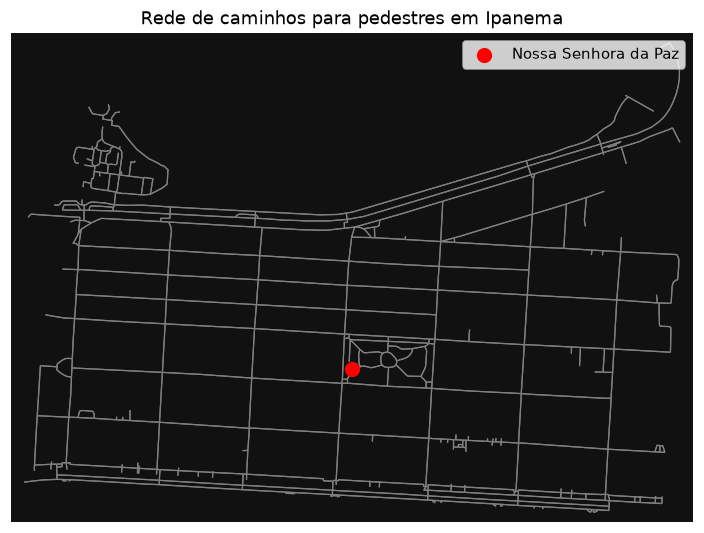

In [22]:
fig, ax = ox.plot_graph(
    G,
    node_size=0,
    edge_color="gray",
    edge_linewidth=0.8,
    show=False,
    close=False
)

ax.scatter(
    estacao.x,
    estacao.y,
    color="red",
    s=80,
    label="Nossa Senhora da Paz",
    zorder=5
)

ax.legend()
ax.set_title("Rede de caminhos para pedestres em Ipanema")

plt.show()


In [23]:
# Grafo e ponto da estação em coordenadas métricas
G_m = ox.project_graph(G, to_crs="EPSG:31983")
estacao_m = metro_metros.loc[
    metro_metros["nome"] == "Nossa Senhora da Paz", "geometry"
].iloc[0]

no_estacao = ox.distance.nearest_nodes(G_m, estacao_m.x, estacao_m.y)

# Origem apenas para o teste: nó a cerca de 450 m em linha reta
no_origem = min(
    G_m.nodes,
    key=lambda n: abs(math.hypot(
        G_m.nodes[n]["x"] - estacao_m.x,
        G_m.nodes[n]["y"] - estacao_m.y
    ) - 450)
)
print("Nó de origem:", no_origem, "| Nó da estação:", no_estacao)


Nó de origem: 13286667177 | Nó da estação: 4570587710


In [24]:
# Coordenadas dos dois nós
origem = G_m.nodes[no_origem]
destino = G_m.nodes[no_estacao]

# Distância em linha reta
dist_reta = math.hypot(
    origem["x"] - destino["x"],
    origem["y"] - destino["y"]
)

# Menor caminho pela rede de ruas
rota = nx.shortest_path(
    G_m,
    source=no_origem,
    target=no_estacao,
    weight="length"
)

dist_ruas = nx.shortest_path_length(
    G_m,
    source=no_origem,
    target=no_estacao,
    weight="length"
)

print(f"Distância em linha reta: {dist_reta:.1f} m")
print(f"Distância pelas ruas: {dist_ruas:.1f} m")


Distância em linha reta: 451.2 m
Distância pelas ruas: 743.5 m


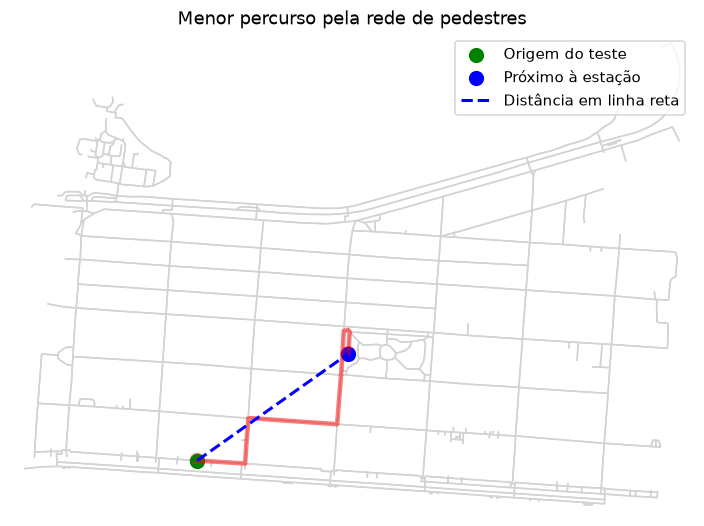

In [25]:
fig, ax = ox.plot_graph_route(
    G_m,
    rota,
    route_color="red",
    route_linewidth=3,
    node_size=0,
    edge_color="lightgray",
    bgcolor="white",
    show=False,
    close=False
)

ax.scatter(
    origem["x"], origem["y"],
    color="green", s=80,
    label="Origem do teste"
)

ax.scatter(
    destino["x"], destino["y"],
    color="blue", s=80,
    label="Próximo à estação"
)

ax.set_title("Menor percurso pela rede de pedestres")

# Mostrar a distância em linha reta
ax.plot(
    [origem["x"], destino["x"]],
    [origem["y"], destino["y"]],
    color="blue",
    linestyle="--",
    linewidth=2,
    label="Distância em linha reta"
)

ax.legend()

plt.show()


O teste demonstra a diferença entre distância reta e percurso na rede atual; não representa imóveis do ITBI nem uma reconstrução histórica das ruas. Os comprimentos calculados estão na saída acima.

## 6. Limitações e próxima entrega

Validar a atribuição individual dos anos do VLT e a cronologia do BRT/BRS. Itamaraty permanece sem ano. A integração desta entrega calcula distâncias a pontos de Metrô, BRT e VLT; BRS será incluído após a definição de seu critério de acesso.

In [26]:
assert pontos_transporte.crs.to_epsg() == 31983
assert pontos_transporte.geometry.geom_type.eq("Point").all()
assert pontos_transporte.geometry.notna().all()
assert pontos_ate_2024["ano_inicio"].between(1900,2024).all()
assert not pontos_ate_2024["ano_inicio"].isna().any()
print("Verificações de geometria e disponibilidade temporal concluídas.")

Verificações de geometria e disponibilidade temporal concluídas.
